In [77]:
import pandas as pd

df = pd.read_csv("concrete_data.csv")
df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [79]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [80]:
import numpy as np

print(f"Number of samples with zero fly ash content:",(df["fly_ash"]==0).sum())
print("\n")
print(f"Number of Zero Values in Each Column:")
print((df == 0).sum(axis = 0))

Number of samples with zero fly ash content: 566


Number of Zero Values in Each Column:
cement                             0
blast_furnace_slag               471
fly_ash                          566
water                              0
superplasticizer                 379
coarse_aggregate                   0
fine_aggregate                     0
age                                0
concrete_compressive_strength      0
dtype: int64


1,030 筆資料中，有 566 筆沒有添加飛灰。<br>
這個結果值得注意。因為 fly_ash = 0 很可能代表材料配方中沒有使用飛灰，而不是缺失值。
因此，不能直接將這些 0 當成 NaN 刪除。

In [81]:
duplicates_all = df.loc[df.duplicated()]
print("Number of rows in duplicate groups:", len(duplicates_all))
duplicates_all

Number of rows in duplicate groups: 25


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
123,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29


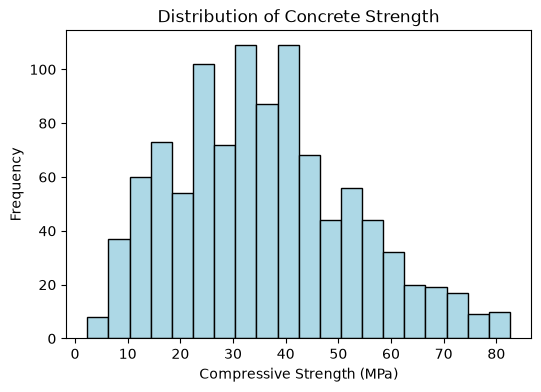

<Figure size 640x480 with 0 Axes>

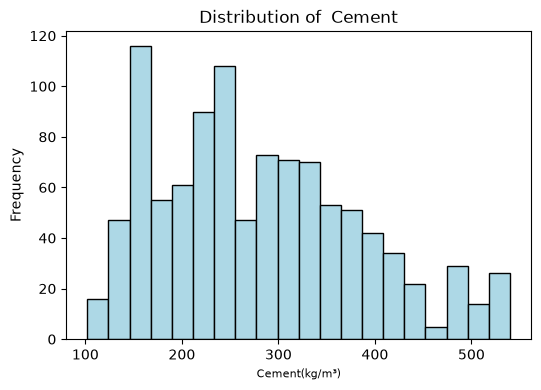

<Figure size 640x480 with 0 Axes>

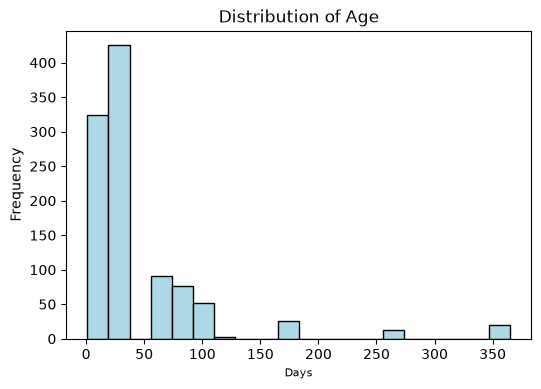

<Figure size 640x480 with 0 Axes>

In [7]:
from matplotlib import pyplot as plt

plt.figure(figsize=(6,4))
plt.hist(df["concrete_compressive_strength"], 
         bins=20, 
         color = "lightblue", 
         edgecolor='black'
        )
plt.title("Distribution of Concrete Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.show()
plt.clf()

plt.figure(figsize=(6,4))
plt.hist(df["cement"], 
         bins=20, 
         color = "lightblue", 
         edgecolor='black'
        )
plt.title("Distribution of  Cement")
plt.xlabel("Cement(kg/m³)", fontsize=8)
plt.ylabel("Frequency")
plt.show()
plt.clf()

plt.figure(figsize=(6,4))
plt.hist(df["age"], 
         bins=20, 
         color = "lightblue", 
         edgecolor='black'
        )
plt.title("Distribution of Age")
plt.xlabel("Days", fontsize=8)
plt.ylabel("Frequency")
plt.show()
plt.clf()


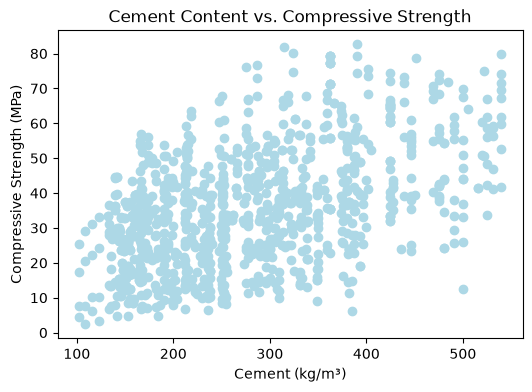

In [8]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["cement"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Cement (kg/m³)")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Cement Content vs. Compressive Strength")

plt.show()

In [9]:
import scipy.stats as stats

r,p = stats.pearsonr(df["cement"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

0.49783191932415743
P-value: 1.324183307226925e-65


セメント量と圧縮強度の間には、中程度の正の相関が認められた（r = 0.498）。

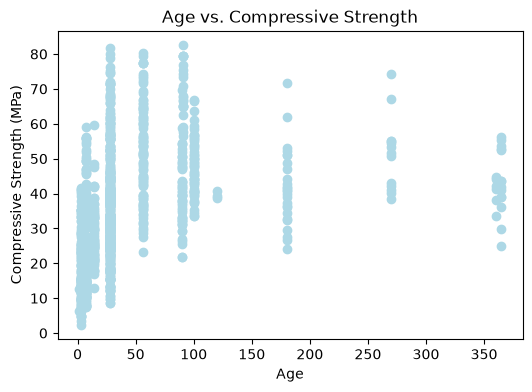

In [10]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["age"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Age")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Age vs. Compressive Strength")

plt.show()

In [11]:
import scipy.stats as stats

r,p = stats.pearsonr(df["age"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

0.3288730007799874
P-value: 2.106340553631996e-27


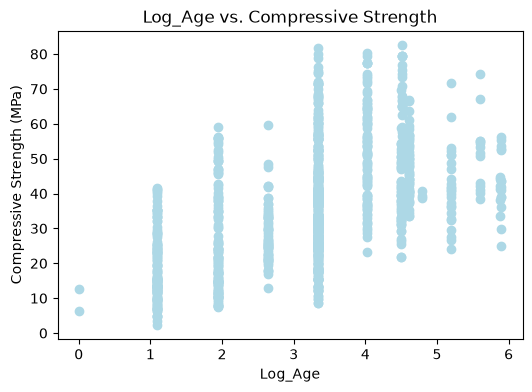

In [12]:
import numpy as np

df["log_age"] = np.log(df["age"])

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["log_age"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Log_Age")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Log_Age vs. Compressive Strength")

plt.show()

In [13]:
r,p = stats.pearsonr(df["log_age"], df["concrete_compressive_strength"])
print(f"The correalation of log_age and concrete_compressive_strength:",r)
print(f"P-value:",p)

The correalation of log_age and concrete_compressive_strength: 0.5521803859561103
P-value: 2.911296350747831e-83


|項目	|Age（原始）|	log(Age)（轉換後）|
|:--|:--|:--|
|Pearson r	|0.3289|	0.5522|
|p-value	|2.11 × 10⁻²⁷	|2.91 × 10⁻⁸³|
|相關方向	|正相關	|正相關|
|線性相關程度	|偏弱至中等	|中等|
|散佈圖	|無明顯直線趨勢	|正向趨勢較清楚|

進一步比較 R²<br>
如果我們分別建立只有一個解釋變數、包含截距的簡單線性回歸模型，則：$ R^2=r^2 $<br>
因此：<br>

|模型|	R²|
|:--|:--|
|Strength ~ Age	|0.108|
|Strength ~ log(Age)	|0.305|

這代表：<br>
原始 Age 的簡單線性模型，能解釋約 10.8% 的抗壓強度樣本變異。<br>
log(Age) 的簡單線性模型，能解釋約 30.5% 的抗壓強度樣本變異。<br>
在這份資料中，對數轉換確實改善了簡單線性模型的擬合程度。<br>
但仍有約 69.5% 的樣本變異未被這個模型解釋。這也提醒我們，材料配方等其他變數可能非常重要。

二、為什麼 log 轉換會改善相關性？

原始模型假設：

$$ Y=\beta_0+\beta_1 Age+\varepsilon $$

代表 Age 每增加一天，抗壓強度的預期變化量固定。

但混凝土強度的發展通常不是這種模式。

例如：

養護時間從 7 天增加到 14 天，與從 180 天增加到 187 天，強度的增加量未必相同。

對數模型則是：

$$ Y=\beta_0+\beta_1\ln(Age)+\varepsilon $$

它允許養護時間增加時，抗壓強度的增加速度逐漸減緩。

假設 \(\beta_1>0\)，模型預測的曲線便會隨 Age 增加而上升，但斜率逐漸下降。

這可能更符合混凝土強度隨養護時間發展的特性。

不過，目前我們還不能說這是最佳模型，因為尚未進行殘差分析，也還沒有控制其他材料配方。

三、你的散佈圖還透露了一個重要問題

仔細觀察，你會發現：

即使轉換成 log_age，在同一個養護天數下，抗壓強度仍然有很大的差異。

例如：

在 log_age ≈ 3.33（Age = 28 天）附近，抗壓強度從約 10 MPa 到 80 MPa 都有。

這表示：

養護天數不是決定抗壓強度的唯一因素。

這也是為什麼接下來我建議使用多元回歸。

我們可以同時考慮：

$$ \begin{aligned} Strength =\;&\beta_0+\beta_1 Cement\\ &+\beta_2 Water\\ &+\beta_3 \ln(Age)+\cdots+\varepsilon \end{aligned} $$

如此一來，就能分析在控制其他材料成分後，養護天數與抗壓強度的關聯。

養生期間（Age）と圧縮強度の関係についてPearsonの相関係数を算出したところ、r = 0.329であり、正の相関が確認された。

散布図から非線形な関係が示唆されたため、養生期間を自然対数変換したうえで再度相関分析を行った。その結果、相関係数はr = 0.552に上昇し、単回帰モデルの決定係数も0.108から0.305に改善した。

以上より、養生期間を対数変換することで、圧縮強度との関係をより適切に記述できる可能性が示された。ただし、材料配合条件などの影響を考慮した追加分析が必要である。

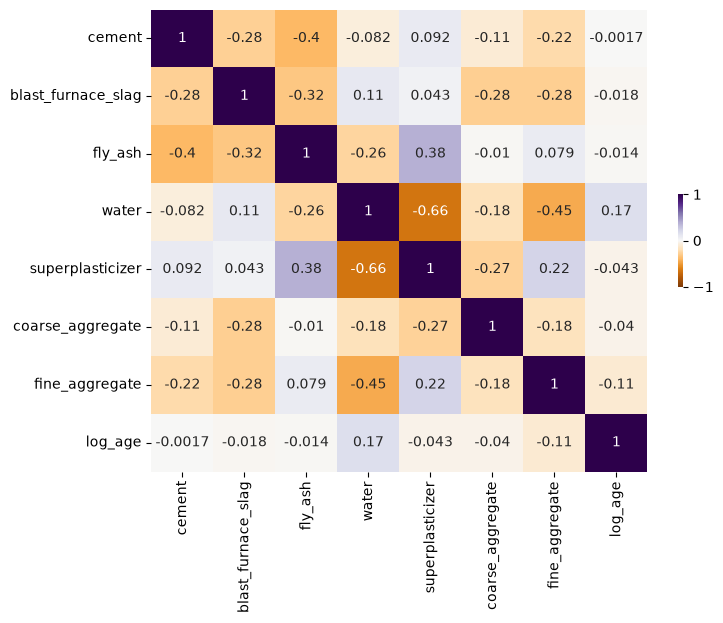

In [33]:
import seaborn as sns

log_df = df.drop(columns=["age","concrete_compressive_strength"])
plt.figure(figsize=(8,6))

corr_grid = log_df.corr()
sns.heatmap(corr_grid,
            xticklabels=corr_grid.columns, 
            yticklabels=corr_grid.columns, 
            vmin=-1, center=0, 
            vmax=1, cmap='PuOr', 
            annot=True, cbar_kws={'shrink': .2})

plt.show()


In [24]:
print(df.columns.tolist())

['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength', 'log_age']


In [25]:
df.columns = df.columns.str.strip()

features = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "log_age"
]

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X = df[features]
X_const = sm.add_constant(X)

cement_vif = variance_inflation_factor(
    X_const.values, 1
)

print("Cement VIF:", cement_vif)

Cement VIF: 7.532370397252844


In [30]:
for i in range(1, X_const.shape[1]):
    vif = variance_inflation_factor(
        X_const.values, i
    )

    print(X_const.columns[i], vif)

cement 7.532370397252844
blast_furnace_slag 7.279188401642309
fly_ash 6.141118268919181
water 6.983870077634611
superplasticizer 2.980300016573899
coarse_aggregate 5.088962191524861
fine_aggregate 7.030352467835508
log_age 1.0523021187261536


In [31]:
vif_df = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X_const.values, i)
        for i in range(1, X_const.shape[1])
    ]
})

vif_df

,Feature,VIF
0,cement,7.532370
1,blast_furnace_slag,7.279188
2,fly_ash,6.141118
3,water,6.983870
4,superplasticizer,2.980300
5,coarse_aggregate,5.088962
6,fine_aggregate,7.030352
7,log_age,1.052302


一般常用的參考標準如下：

|VIF	|判斷|
|:--|:--|
|1	|幾乎沒有共線性|
|1～5	|通常沒有嚴重問題|
|5～10	|值得注意|
|>10	|可能有嚴重多重共線性|

|排名	|變數	|VIF	判斷|
|:--|:--|:--|
|1|	cement|	7.53|	⚠️ 偏高|
|2|	blast_furnace_slag|	7.28|	⚠️ 偏高|
|3|	fine_aggregate	|7.03	|⚠️ 偏高|
|4|	water|	6.98|	⚠️ 偏高|
|5|	fly_ash|	6.14	|⚠️ 偏高|
|6|	coarse_aggregate	|5.09	|⚠️ 略高|
|7|	superplasticizer|	2.98|	相對較低|
|8|	log_age	|1.05	|幾乎沒有共線性|

8 個解釋變數中：
6 個變數的 VIF > 5
2 個變數的 VIF < 5
沒有任何變數的 VIF > 10

依照常見經驗標準，部分變數存在值得注意的多重共線性，但還不能直接認定模型無法使用。

為什麼相關係數不高，VIF 卻偏高？

這是這次分析最重要的統計觀念。

先前你發現：

cement × fly_ash：r = -0.40
water × superplasticizer：r = -0.66
water × fine_aggregate：r = -0.45

兩兩相關係數都沒有超過 0.7。

但是現在：

$$ VIF_{\text{cement}}=7.53 $$

為什麼？

因為 VIF 不是只檢查兩個變數。

它檢查的是：

某個解釋變數能在多大程度上被其他所有解釋變數共同解釋。

例如，cement 的 VIF 為 7.53。

利用公式：

$$ VIF_j=\frac{1}{1-R_j^2} $$

可以反推：

$$ R_j^2=1-\frac{1}{7.53} $$ $$ R_j^2\approx0.867 $$

這代表：

其他七個解釋變數共同可以解釋約 86.7% 的 cement 樣本變異。

因此，即使 cement 與某個單一變數的相關性不高，它仍可能與其他多個變數存在較強的線性依賴。

這就是多重共線性。

為什麼混凝土資料容易出現這種情況？

這與資料的物理意義有關。

混凝土由多種材料組成：

水泥
高爐爐渣
飛灰
水
粗骨材
細骨材
減水劑

這些材料的配合比例不是完全獨立的。

例如，如果增加水泥含量，其他材料的使用量可能需要調整。

因此，各種材料之間可能存在結構性的關聯。

這也能解釋為什麼多個材料變數的 VIF 都偏高。

不過，這只是合理的領域解釋；是否存在固定總量限制，仍需要根據資料的收集方式進一步確認。

In [ ]:
為什麼混凝土資料容易出現這種情況？

這與資料的物理意義有關。

混凝土由多種材料組成：

水泥
高爐爐渣
飛灰
水
粗骨材
細骨材
減水劑

這些材料的配合比例不是完全獨立的。

例如，如果增加水泥含量，其他材料的使用量可能需要調整。

因此，各種材料之間可能存在結構性的關聯。

這也能解釋為什麼多個材料變數的 VIF 都偏高。

不過，這只是合理的領域解釋；是否存在固定總量限制，仍需要根據資料的收集方式進一步確認。

In [35]:
y = df["concrete_compressive_strength"]

import statsmodels.api as sm

X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit()

print(model.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.819
Model:                                       OLS   Adj. R-squared:                  0.817
Method:                            Least Squares   F-statistic:                     575.6
Date:                           Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                                   23:02:19   Log-Likelihood:                -3482.4
No. Observations:                           1030   AIC:                             6983.
Df Residuals:                               1021   BIC:                             7027.
Df Model:                                      8                                         
Covariance Type:                       nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

項目	意義
R-squared	決定係數
Adj. R-squared	調整後決定係數
coef	回歸係數
std err	係數標準誤
t	t 統計量
P>|t|	係數檢定的 p 值
[0.025, 0.975]	95% 信賴區間
F-statistic	整體回歸模型的 F 統計量

In [36]:
fitted = model.fittedvalues

residuals = model.resid

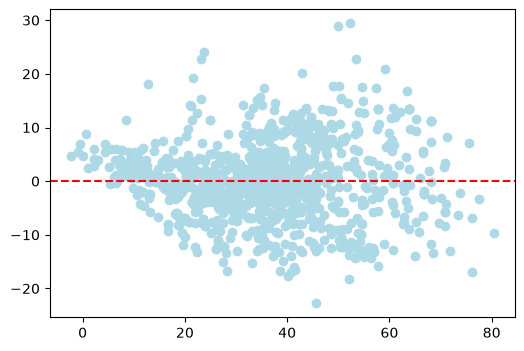

In [40]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(fitted, residuals,color="lightblue" )
ax.axhline(y=0, color="red", linestyle="--")
plt.show()

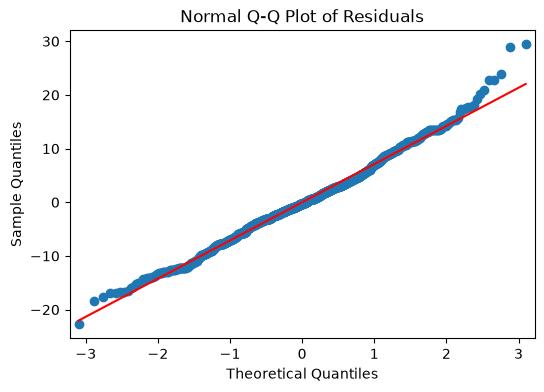

In [43]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))

sm.qqplot(
    residuals,
    line="s",
    ax=ax
)

ax.set_title("Normal Q-Q Plot of Residuals")

plt.show()

In [44]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    residuals,
    X_const
)
print(bp_test)

(np.float64(101.83753665142032), np.float64(1.79709509568583e-18), np.float64(14.002953284975048), np.float64(1.8975927405398625e-19))


In [47]:
bp_df = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

bp_df

,Statistic,Value
0,LM Statistic,1.018375e+02
1,LM p-value,1.797095e-18
2,F Statistic,1.400295e+01
3,F p-value,1.897593e-19


In [48]:
bp_df["Value"].map(lambda x: f"{x:.4g}")

0        101.8
1    1.797e-18
2           14
3    1.898e-19
Name: Value, dtype: str

In [49]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model.resid,
    X_const
)

bp_df = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

bp_df

,Statistic,Value
0,LM Statistic,1.018375e+02
1,LM p-value,1.797095e-18
2,F Statistic,1.400295e+01
3,F p-value,1.897593e-19


In [50]:
robust_model = model.get_robustcov_results(
    cov_type="HC3"
)
print(robust_model.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.819
Model:                                       OLS   Adj. R-squared:                  0.817
Method:                            Least Squares   F-statistic:                     566.1
Date:                           Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                                   23:21:44   Log-Likelihood:                -3482.4
No. Observations:                           1030   AIC:                             6983.
Df Residuals:                               1021   BIC:                             7027.
Df Model:                                      8                                         
Covariance Type:                             HC3                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

In [51]:
comparison = pd.DataFrame({
    "Feature": model.model.exog_names,
    "Coefficient": model.params.values,
    "OLS_SE": model.bse.values,
    "HC3_SE": robust_model.bse,
    "OLS_p": model.pvalues.values,
    "HC3_p": robust_model.pvalues
})

comparison

,Feature,Coefficient,OLS_SE,HC3_SE,OLS_p,HC3_p
0,const,-77.533388,18.330800,22.454848,2.550382e-05,5.774327e-04
1,cement,0.134857,0.005849,0.006819,5.121581e-95,5.950791e-74
2,blast_furnace_slag,0.115945,0.006965,0.008648,3.099533e-55,7.193031e-38
3,fly_ash,0.094391,0.008625,0.009528,1.950061e-26,3.736010e-22
4,water,-0.128817,0.027564,0.034884,3.359978e-06,2.335979e-04
5,superplasticizer,0.118822,0.064366,0.077040,6.517613e-02,1.232981e-01
6,coarse_aggregate,0.029681,0.006462,0.007823,4.912984e-06,1.570142e-04
7,fine_aggregate,0.035989,0.007366,0.008824,1.194949e-06,4.881471e-05
8,log_age,8.746595,0.191768,0.195395,1.438418e-248,5.003595e-243


In [52]:
robust_model = model.get_robustcov_results(
    cov_type="HC3"
)

print(robust_model.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.819
Model:                                       OLS   Adj. R-squared:                  0.817
Method:                            Least Squares   F-statistic:                     566.1
Date:                           Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                                   23:22:25   Log-Likelihood:                -3482.4
No. Observations:                           1030   AIC:                             6983.
Df Residuals:                               1021   BIC:                             7027.
Df Model:                                      8                                         
Covariance Type:                             HC3                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

In [53]:
import numpy as np

rmse = np.sqrt(np.mean((y - fitted) ** 2))

print(f"RMSE: {rmse:.3f} MPa")

RMSE: 7.113 MPa


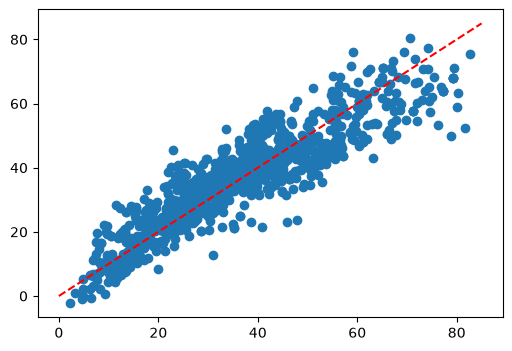

In [55]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["concrete_compressive_strength"],fitted)
ax.plot([0, 85], [0, 85], "r--")


ax.set_xlabel("Actual Strength (MPa)")
ax.set_ylabel("Predicted Strength (MPa)")
ax.set_title("Actual vs. Predicted Compressive Strength")

plt.tight_layout()
plt.show()